### Robustness Evaluation

In [5]:
# Load Libraries needed for data handling & visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import ravel
from matplotlib import pyplot as plt


# Libraries for Machine Learning

from sklearn import datasets
from sklearn import metrics
from sklearn.model_selection import train_test_split 
from sklearn.metrics import mean_squared_error, r2_score   
from sklearn.model_selection import train_test_split
import lightgbm as lgb

# Explainability

import shap
import lime
import lime.lime_tabular

# Others

import os
import warnings
from math import sqrt
from random import shuffle

warnings.simplefilter(action='ignore')

In [6]:
# Create training dataset
df = pd.read_csv('datasets/kc_house_data.csv')
y = df[['price']] # target
X = df.drop('price', axis=1) # features
X = df.drop('date', axis=1)

# Convert to numpy for training & predictions
X = X.to_numpy()
y = ravel(y.to_numpy())

In [3]:
def create_model(X_train,X_val,y_train,y_val):
    model = lgb.LGBMRegressor(deterministic = True)
    model.fit(X_train,y_train, eval_set = [(X_val,y_val)],early_stopping_rounds = 5, eval_metric = 'rmse')
    return model

In [5]:
# Split train and evaluation sets from our training dataset / Create the model

X_train,X_val,y_train,y_val = train_test_split(X,y, test_size=0.20)
reg_model = create_model(X_train,X_val,y_train,y_val);

[1]	valid_0's rmse: 331122	valid_0's l2: 1.09642e+11
[2]	valid_0's rmse: 298728	valid_0's l2: 8.92382e+10
[3]	valid_0's rmse: 269534	valid_0's l2: 7.26486e+10
[4]	valid_0's rmse: 243340	valid_0's l2: 5.92144e+10
[5]	valid_0's rmse: 219749	valid_0's l2: 4.82895e+10
[6]	valid_0's rmse: 198643	valid_0's l2: 3.94591e+10
[7]	valid_0's rmse: 179710	valid_0's l2: 3.22955e+10
[8]	valid_0's rmse: 162745	valid_0's l2: 2.64859e+10
[9]	valid_0's rmse: 146952	valid_0's l2: 2.15947e+10
[10]	valid_0's rmse: 133080	valid_0's l2: 1.77102e+10
[11]	valid_0's rmse: 120662	valid_0's l2: 1.45592e+10
[12]	valid_0's rmse: 109831	valid_0's l2: 1.20629e+10
[13]	valid_0's rmse: 100034	valid_0's l2: 1.00067e+10
[14]	valid_0's rmse: 91083.3	valid_0's l2: 8.29616e+09
[15]	valid_0's rmse: 83420.2	valid_0's l2: 6.95893e+09
[16]	valid_0's rmse: 76553.8	valid_0's l2: 5.86048e+09
[17]	valid_0's rmse: 70618.6	valid_0's l2: 4.98699e+09
[18]	valid_0's rmse: 65425.7	valid_0's l2: 4.28052e+09
[19]	valid_0's rmse: 60884.1	val

In [ ]:
# Getting prediction for the independent test set

y_predict_MG1_Torque = reg_model.predict(Xt)

In [ ]:
# Split train and evaluation sets from our training dataset / Create the model

X_train,X_val,y_train,y_val = train_test_split(X,y, test_size=0.20)
reg_model = create_model(X_train,X_val,y_train,y_val);

In [6]:
# Getting prediction for the independent test set

predictions = reg_model.predict(X_val)

In [12]:
print('R2 score: ', metrics.r2_score(y_val, predictions))
print('Root Mean square error: ', metrics.mean_squared_error(y_val, predictions, squared=False))

R2 score:  0.9954101830134354
Root Mean square error:  24881.708896249034


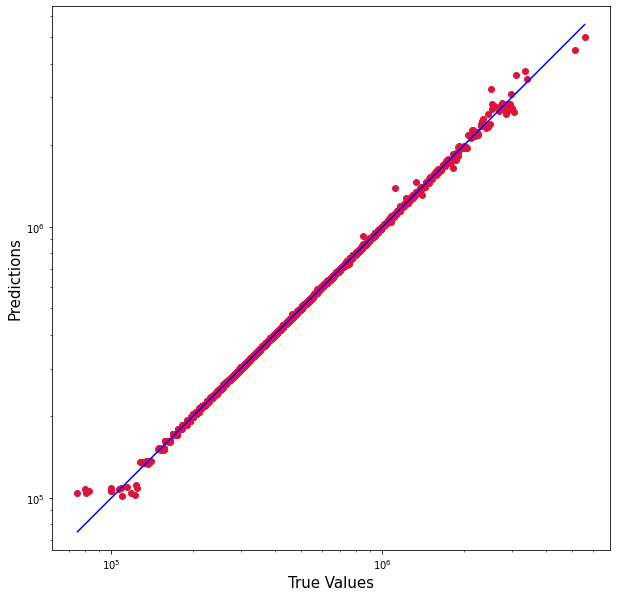

In [17]:
plt.figure(figsize=(10,10))
plt.scatter(y_val, predictions, c='crimson')
plt.yscale('log')
plt.xscale('log')

p1 = max(max(predictions), max(y_val))
p2 = min(min(predictions), min(y_val))
plt.plot([p1, p2], [p1, p2], 'b-')
plt.xlabel('True Values', fontsize=15)
plt.ylabel('Predictions', fontsize=15)
plt.axis('equal')
plt.show()